In [10]:
import os
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# ==========================================
# 1. DOWNLOAD AND PREPARE DATA
# ==========================================
print("Downloading Bitcoin data...")
df = yf.download("BTC-USD", start="2023-01-01", progress=False)

# Flatten columns if MultiIndex is returned by yfinance
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Create target variable (next day's Close price)
df['Prediction'] = df['Close'].shift(-1)
df = df.dropna()

# Define features (X) and target (y)
X = df[['Open', 'High', 'Low', 'Close', 'Volume']]
y = df['Prediction']

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# ==========================================
# 2. TRAIN MACHINE LEARNING MODEL
# ==========================================
print("Training Random Forest Regressor model...")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate model performance
predictions = model.predict(X_test)
score = r2_score(y_test, predictions)
print(f"Model R2 Score: {score:.4f}")

# ==========================================
# 3. PLOT AND SAVE RESULTS
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Actual Price', color='blue', alpha=0.7)
plt.plot(predictions, label='Predicted Price', color='orange', linestyle='--', alpha=0.9)
plt.title('Bitcoin Price Prediction - Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(True)

# Save the plot as an image file
plot_path = "prediction_plot.png"
plt.savefig(plot_path)
plt.close()
print(f"Plot saved successfully as '{plot_path}'")

# ==========================================
# 4. PREDICT TOMORROW'S PRICE
# ==========================================
latest_data = X.tail(1)
next_day_pred = model.predict(latest_data)[0]
print(f"Predicted Bitcoin Price for Tomorrow: ${next_day_pred:,.2f}")

# ==========================================
# 5. CREATE REQUIRED PROJECT FILES (README & requirements)
# ==========================================
requirements_content = """yfinance==0.2.33
pandas==2.1.4
scikit-learn==1.3.2
matplotlib==3.8.2
"""
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements_content)

readme_content = """# Bitcoin Machine Learning Price Predictor

A simple machine learning project built with Python to predict Bitcoin prices using scikit-learn and yfinance.

## Features
- Downloads historical BTC-USD data automatically.
- Trains a RandomForestRegressor model.
- Evaluates model performance and plots predictions.
- Predicts the next-day price.

## Tech Stack
- Python, Jupyter Notebook
- Pandas, Scikit-Learn, Matplotlib, yfinance
"""
with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("Project files ('requirements.txt' and 'README.md') created successfully!")


Training Random Forest Regressor model...
Model R2 Score: 0.8871
Plot saved successfully as 'prediction_plot.png'
Predicted Bitcoin Price for Tomorrow: $81,793.36
Project files ('requirements.txt' and 'README.md') created successfully!


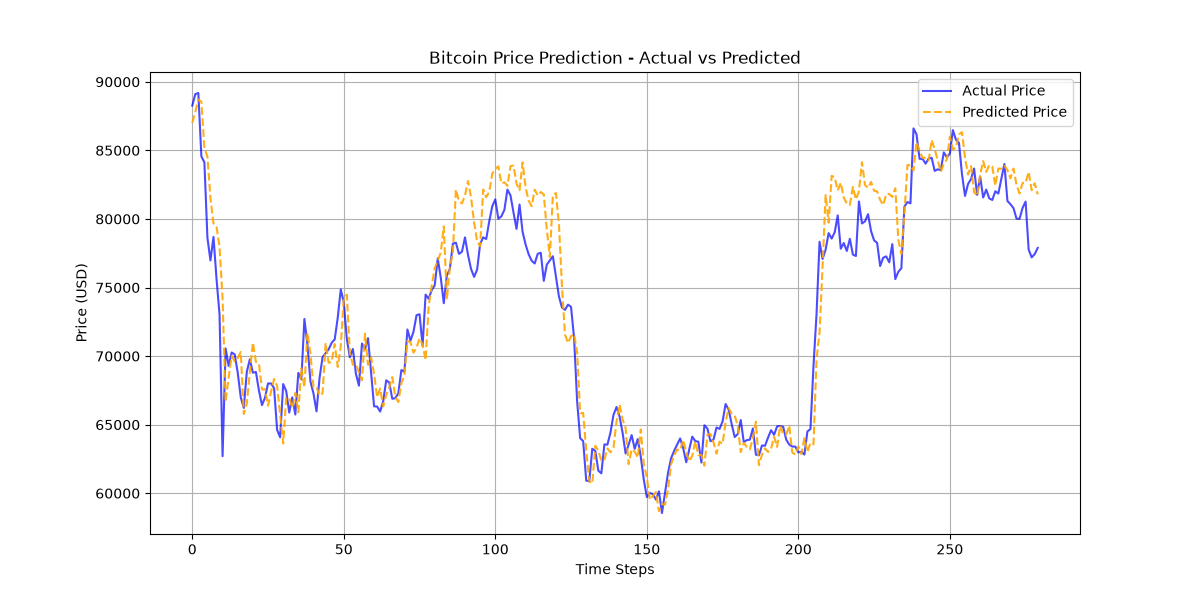

In [11]:
from IPython.display import Image
Image(filename="prediction_plot.png")
